# Cornell vs Jacquard — two complementary regimes

This short notebook makes the paper's strongest framing for using BOTH datasets:
a weaker detector (Cornell, ~73%) and a stronger one (Jacquard, ~93%) put the
rejection rule in DIFFERENT operating regimes, and neither dataset alone tells
the whole story.

**What it needs.** The two score caches produced by the main notebooks:
`scores_cornell.npz` and `scores_jacquard.npz`. Upload both, or point the paths
below at your Drive copies. Everything here is analysis of those caches -- no
training, seconds to run.

In [1]:
# minimal deps; these two modules are all the analysis needs
import importlib
for mod, pkg in [('numpy','numpy'), ('scipy','scipy'), ('matplotlib','matplotlib')]:
    try: importlib.import_module(mod)
    except Exception:
        !pip install -q {pkg}
import numpy as np

In [2]:
%%writefile selective_grasp.py
"""
selective_grasp.py
==================
Rejection rules and risk-coverage analysis for grasp prediction.

Input contract
--------------
This module deliberately knows nothing about GR-ConvNet. It consumes a cached
.npz produced by `extract_scores.py` containing, for N test samples:

    success : (N,) int/bool   1 if the predicted grasp satisfies the rectangle
                              metric (IoU > 0.25 and angle error < 30 deg)
    s_conf  : (N,) float      S1  1 - peak quality
    s_ent   : (N,) float      S2  spatial entropy of the quality map
    s_mc    : (N,) float      S3  MC-dropout pose dispersion      (optional)
    s_ev_ep : (N,) float      S4  evidential epistemic dispersion (optional)
    s_ev_al : (N,) float      S4  evidential aleatoric dispersion (optional)
    s_topk  : (N,) float      S5  top-k grasp disagreement

Convention: for every score, LARGER = LESS TRUSTWORTHY. Accept iff s <= tau.

Usage
-----
    python selective_grasp.py --scores scores.npz --alpha 0.05 --delta 0.10 \
                              --out results/

Outputs Table 1 / Table 2 / Table 3 of the paper as CSV + markdown, and the
risk-coverage figure.
"""

from __future__ import annotations

import argparse
import itertools
import json
import os
from dataclasses import dataclass, asdict

import numpy as np
from scipy.stats import binom

EPS = 1e-12

# numpy >= 2.0 renamed trapz -> trapezoid
_trapz = getattr(np, "trapezoid", None) or np.trapz


# --------------------------------------------------------------------------- #
# 1. Risk-coverage machinery
# --------------------------------------------------------------------------- #

def risk_coverage_curve(scores: np.ndarray, loss: np.ndarray):
    """Full risk-coverage curve, evaluated at every achievable coverage.

    Parameters
    ----------
    scores : (N,) larger = less trustworthy
    loss   : (N,) in [0,1]; here the 0/1 failure indicator

    Returns
    -------
    coverage : (N,) increasing from 1/N to 1
    risk     : (N,) selective risk at each coverage
    """
    order = np.argsort(scores, kind="mergesort")     # ascending uncertainty
    l_sorted = loss[order]
    n = len(loss)
    coverage = np.arange(1, n + 1) / n
    risk = np.cumsum(l_sorted) / np.arange(1, n + 1)
    return coverage, risk


def aurc(scores: np.ndarray, loss: np.ndarray) -> float:
    """Area under the risk-coverage curve (lower is better)."""
    _, risk = risk_coverage_curve(scores, loss)
    return float(np.mean(risk))


def oracle_aurc(loss: np.ndarray) -> float:
    """AURC of the hindsight-optimal gate (sort by true loss)."""
    return aurc(loss.astype(float), loss)


def excess_aurc(scores: np.ndarray, loss: np.ndarray) -> float:
    return aurc(scores, loss) - oracle_aurc(loss)


def risk_at_coverage(scores: np.ndarray, loss: np.ndarray, cov: float) -> float:
    """Selective risk when the gate accepts the `cov` fraction of lowest scores."""
    coverage, risk = risk_coverage_curve(scores, loss)
    idx = int(np.clip(np.searchsorted(coverage, cov), 0, len(risk) - 1))
    return float(risk[idx])


def coverage_at_risk(scores: np.ndarray, loss: np.ndarray, alpha: float,
                     n_min: int = 30) -> float:
    """Largest coverage whose empirical selective risk stays <= alpha.

    Returns 0.0 if no threshold with at least `n_min` accepted samples works.
    """
    coverage, risk = risk_coverage_curve(scores, loss)
    n = len(loss)
    valid = (risk <= alpha) & (np.arange(1, n + 1) >= n_min)
    return float(coverage[valid].max()) if valid.any() else 0.0


def ause(scores: np.ndarray, loss: np.ndarray) -> float:
    """Area under the sparsification error curve.

    IMPORTANT: with a *binary* loss the sparsification curve is exactly the
    reversed risk-coverage curve, and since sp_score >= sp_oracle pointwise,
    this quantity is algebraically identical to E-AURC. The column is therefore
    redundant here. To make the paper's ranking-vs-operating-point contrast
    real, compute AUSE on a *continuous* error (IoU deficit, angle error, or
    the regression residual used in the ICARCV benchmark) by passing that array
    as `loss` instead of the 0/1 indicator. Then AUSE and AURC genuinely
    measure different things and may disagree.
    """
    n = len(loss)
    order_s = np.argsort(-scores, kind="mergesort")   # remove most uncertain first
    order_o = np.argsort(-loss.astype(float), kind="mergesort")

    def sparsification(order):
        l = loss[order]
        # mean loss of the remaining set after removing the first k
        rem = np.cumsum(l[::-1])[::-1]
        counts = np.arange(n, 0, -1)
        return rem / counts

    sp_s = sparsification(order_s)
    sp_o = sparsification(order_o)
    return float(np.mean(np.abs(sp_s - sp_o)))


# --------------------------------------------------------------------------- #
# 2. Distribution-free risk control (Learn-then-Test)
# --------------------------------------------------------------------------- #

def _h1(a: float, b: float) -> float:
    """KL between two Bernoullis, used by the Hoeffding bound."""
    a = min(max(a, EPS), 1 - EPS)
    b = min(max(b, EPS), 1 - EPS)
    return a * np.log(a / b) + (1 - a) * np.log((1 - a) / (1 - b))


def hb_p_value(risk_hat: float, n: int, alpha: float) -> float:
    """Hoeffding-Bentkus p-value for H0: R > alpha, with bounded loss in [0,1].

    Small p means we can safely reject H0, i.e. the true risk is <= alpha.
    """
    if n <= 0:
        return 1.0
    if risk_hat >= alpha:
        return 1.0
    p_hoeff = float(np.exp(-n * _h1(risk_hat, alpha)))
    p_bent = float(np.e * binom.cdf(np.ceil(n * risk_hat), n, alpha))
    return min(1.0, min(p_hoeff, p_bent))


@dataclass
class CalibrationResult:
    tau: float | tuple
    p_value: float
    cal_risk: float
    cal_coverage: float
    n_accepted: int
    valid: bool          # False when no threshold could be certified


def ltt_calibrate_single(scores: np.ndarray, loss: np.ndarray,
                         alpha: float, delta: float,
                         n_grid: int = 200, n_min: int = 50) -> CalibrationResult:
    """Fixed-sequence Learn-then-Test for a single-threshold rejection rule.

    Walks candidate thresholds from most conservative (lowest coverage) to most
    liberal, rejecting H_j: R(tau_j) > alpha while p_j <= delta, and stops at
    the first failure. Guarantees P(R(tau_hat) <= alpha) >= 1 - delta.
    """
    qs = np.linspace(0.0, 1.0, n_grid + 1)[1:]           # increasing coverage
    grid = np.quantile(scores, qs)
    grid = np.unique(grid)                                # keeps ascending order

    best = CalibrationResult(np.nan, 1.0, np.nan, 0.0, 0, False)
    for tau in grid:
        acc = scores <= tau
        n_acc = int(acc.sum())
        if n_acc < n_min:
            continue                                      # too few to certify
        r_hat = float(loss[acc].mean())
        p = hb_p_value(r_hat, n_acc, alpha)
        if p <= delta:
            best = CalibrationResult(float(tau), p, r_hat,
                                     n_acc / len(scores), n_acc, True)
        else:
            break                                         # fixed-sequence stop
    return best


def ltt_calibrate_conjunctive(score_a: np.ndarray, score_b: np.ndarray,
                              loss: np.ndarray, alpha: float, delta: float,
                              n_grid: int = 20, n_min: int = 50,
                              path_frac: float = 0.5,
                              rng: np.random.Generator | None = None
                              ) -> CalibrationResult:
    """LTT for the conjunctive rule  accept iff (s_a <= t_a) and (s_b <= t_b).

    The threshold space is 2-D so no total order exists. We split the
    calibration set: the first half only *orders* the candidate pairs by their
    coverage (defining a fixed sequence), the second half runs the hypothesis
    tests. Ordering on independent data keeps the sequence pre-specified with
    respect to the testing data, which is what fixed-sequence testing requires.
    """
    rng = rng or np.random.default_rng(0)
    n = len(loss)
    perm = rng.permutation(n)
    n_path = int(path_frac * n)
    idx_path, idx_test = perm[:n_path], perm[n_path:]

    qs = np.linspace(0.0, 1.0, n_grid + 1)[1:]
    grid_a = np.unique(np.quantile(score_a, qs))
    grid_b = np.unique(np.quantile(score_b, qs))
    pairs = list(itertools.product(grid_a, grid_b))

    # order the sequence by coverage measured on the path half only
    cov_path = [
        float(((score_a[idx_path] <= ta) & (score_b[idx_path] <= tb)).mean())
        for ta, tb in pairs
    ]
    order = np.argsort(cov_path)                     # conservative -> liberal

    sa, sb, ls = score_a[idx_test], score_b[idx_test], loss[idx_test]
    best = CalibrationResult((np.nan, np.nan), 1.0, np.nan, 0.0, 0, False)
    for j in order:
        ta, tb = pairs[j]
        acc = (sa <= ta) & (sb <= tb)
        n_acc = int(acc.sum())
        if n_acc < n_min:
            continue
        r_hat = float(ls[acc].mean())
        p = hb_p_value(r_hat, n_acc, alpha)
        if p <= delta:
            best = CalibrationResult((float(ta), float(tb)), p, r_hat,
                                     n_acc / len(ls), n_acc, True)
        else:
            break
    return best


def naive_threshold(scores: np.ndarray, loss: np.ndarray, alpha: float,
                    n_min: int = 50) -> float:
    """The uncalibrated baseline: largest tau with empirical cal risk <= alpha.

    Included precisely to show it over-covers and violates alpha on fresh data.
    """
    order = np.argsort(scores, kind="mergesort")
    s_sorted, l_sorted = scores[order], loss[order]
    run = np.cumsum(l_sorted) / np.arange(1, len(loss) + 1)
    ok = (run <= alpha) & (np.arange(1, len(loss) + 1) >= n_min)
    return float(s_sorted[ok][-1]) if ok.any() else float(s_sorted[0])


# --------------------------------------------------------------------------- #
# 3. Logistic fusion (rule R3)
# --------------------------------------------------------------------------- #

def fit_logistic_fusion(S_cal: np.ndarray, loss_cal: np.ndarray,
                        n_iter: int = 500, lr: float = 0.5, l2: float = 1e-3):
    """Plain gradient-descent logistic regression predicting failure.

    Kept dependency-free and tiny on purpose; swap for sklearn if preferred.
    Returns (w, b, mu, sd) where mu/sd standardise the score matrix.
    """
    mu, sd = S_cal.mean(0), S_cal.std(0) + EPS
    X = (S_cal - mu) / sd
    y = loss_cal.astype(float)
    w = np.zeros(X.shape[1])
    b = 0.0
    for _ in range(n_iter):
        z = X @ w + b
        p = 1.0 / (1.0 + np.exp(-z))
        g = p - y
        w -= lr * (X.T @ g / len(y) + l2 * w)
        b -= lr * g.mean()
    return w, b, mu, sd


def apply_logistic_fusion(S: np.ndarray, params) -> np.ndarray:
    w, b, mu, sd = params
    z = ((S - mu) / sd) @ w + b
    return 1.0 / (1.0 + np.exp(-z))          # predicted failure prob = score


# --------------------------------------------------------------------------- #
# 4. Experiment drivers -> the three tables of the paper
# --------------------------------------------------------------------------- #

SCORE_KEYS = [
    ("s_conf",  "S1 negative peak quality"),
    ("s_ent",   "S2 quality-map entropy"),
    ("s_mc",    "S3 MC-dropout dispersion"),
    ("s_ev_ep", "S4 evidential (epistemic)"),
    ("s_ev_al", "S4 evidential (aleatoric)"),
    ("s_topk",  "S5 top-k disagreement"),
]


def load_scores(path: str):
    d = np.load(path)
    loss = 1.0 - d["success"].astype(float)
    scores = {k: d[k].astype(float) for k, _ in SCORE_KEYS if k in d}
    if not scores:
        raise ValueError("no recognised score arrays found in %s" % path)
    return scores, loss


def table1(scores: dict, loss: np.ndarray, alphas=(0.10, 0.05)):
    """Which score gives the best operating curve."""
    rows = []
    for key, name in SCORE_KEYS:
        if key not in scores:
            continue
        s = scores[key]
        row = {
            "score": name,
            "AURC": aurc(s, loss),
            "E-AURC": excess_aurc(s, loss),
            "AUSE": ause(s, loss),
            "R@90": risk_at_coverage(s, loss, 0.90),
            "R@70": risk_at_coverage(s, loss, 0.70),
        }
        for a in alphas:
            row[f"C*(a={a})"] = coverage_at_risk(s, loss, a)
        rows.append(row)
    rows.append({"score": "Oracle", "AURC": oracle_aurc(loss), "E-AURC": 0.0,
                 "AUSE": 0.0, "R@90": risk_at_coverage(loss, loss, 0.90),
                 "R@70": risk_at_coverage(loss, loss, 0.70),
                 **{f"C*(a={a})": coverage_at_risk(loss, loss, a) for a in alphas}})
    return rows


def table2(scores: dict, loss: np.ndarray, alpha: float = 0.05,
           rng: np.random.Generator | None = None):
    """Do combinations help: R1 vs conjunctive R2 vs fused R3."""
    rng = rng or np.random.default_rng(0)
    rows = []

    # R1: best single score by AURC
    singles = {k: aurc(v, loss) for k, v in scores.items()}
    best_key = min(singles, key=singles.get)
    rows.append({"rule": "R1 best single", "scores": best_key,
                 "AURC": singles[best_key],
                 f"C*(a={alpha})": coverage_at_risk(scores[best_key], loss, alpha)})

    # R2: conjunctions of s_conf with each dispersion-style score
    base = "s_conf"
    if base in scores:
        for other in ("s_mc", "s_topk", "s_ev_ep", "s_ent"):
            if other not in scores:
                continue
            cov, risk_c = _conjunctive_curve(scores[base], scores[other], loss)
            rows.append({
                "rule": "R2 conjunctive",
                "scores": f"{base} AND {other}",
                "AURC": float(_trapz(risk_c, cov) / max(cov[-1] - cov[0], EPS)),
                f"C*(a={alpha})": float(cov[risk_c <= alpha].max())
                if (risk_c <= alpha).any() else 0.0,
            })

    # R3: logistic fusion, fitted on half and evaluated on the other half
    keys = [k for k, _ in SCORE_KEYS if k in scores]
    S = np.stack([scores[k] for k in keys], axis=1)
    n = len(loss)
    perm = rng.permutation(n)
    a, b = perm[: n // 2], perm[n // 2:]
    params = fit_logistic_fusion(S[a], loss[a])
    s_fused = apply_logistic_fusion(S[b], params)
    rows.append({"rule": "R3 logistic fusion", "scores": "+".join(keys),
                 "AURC": aurc(s_fused, loss[b]),
                 f"C*(a={alpha})": coverage_at_risk(s_fused, loss[b], alpha)})
    return rows


def _conjunctive_curve(sa: np.ndarray, sb: np.ndarray, loss: np.ndarray,
                       n_grid: int = 25):
    """Pareto risk-coverage frontier of the conjunctive rule over a 2-D grid."""
    qs = np.linspace(0.02, 1.0, n_grid)
    ga, gb = np.quantile(sa, qs), np.quantile(sb, qs)
    pts = []
    for ta, tb in itertools.product(ga, gb):
        acc = (sa <= ta) & (sb <= tb)
        k = int(acc.sum())
        if k < 30:
            continue
        pts.append((k / len(loss), float(loss[acc].mean())))
    pts.sort()
    cov = np.array([p[0] for p in pts])
    rk = np.array([p[1] for p in pts])
    # lower envelope: best (lowest) risk achievable at each coverage or above
    rk = np.minimum.accumulate(rk[::-1])[::-1]
    return cov, rk


def table3(scores: dict, loss: np.ndarray, alpha: float, delta: float,
           n_splits: int = 100, seed: int = 0):
    """Does the calibrated threshold hold, and what does validity cost."""
    rng = np.random.default_rng(seed)
    n = len(loss)
    key = min(scores, key=lambda k: aurc(scores[k], loss))
    s = scores[key]

    rec = {"naive": {"risk": [], "cov": [], "viol": []},
           "ltt": {"risk": [], "cov": [], "viol": []}}

    for _ in range(n_splits):
        perm = rng.permutation(n)
        cal, ev = perm[: n // 2], perm[n // 2:]

        t_naive = naive_threshold(s[cal], loss[cal], alpha)
        res_ltt = ltt_calibrate_single(s[cal], loss[cal], alpha, delta)

        for name, tau in (("naive", t_naive),
                          ("ltt", res_ltt.tau if res_ltt.valid else -np.inf)):
            acc = s[ev] <= tau
            if acc.sum() == 0:
                rec[name]["risk"].append(0.0)
                rec[name]["cov"].append(0.0)
                rec[name]["viol"].append(0.0)
                continue
            r = float(loss[ev][acc].mean())
            rec[name]["risk"].append(r)
            rec[name]["cov"].append(float(acc.mean()))
            rec[name]["viol"].append(float(r > alpha))

    rows = []
    for name in ("naive", "ltt"):
        rows.append({
            "rule": f"{name} (score={key})",
            "alpha": alpha,
            "delta": delta if name == "ltt" else None,
            "mean_eval_risk": float(np.mean(rec[name]["risk"])),
            "violation_rate": float(np.mean(rec[name]["viol"])),
            "mean_coverage": float(np.mean(rec[name]["cov"])),
            "coverage_sd": float(np.std(rec[name]["cov"])),
        })
    rows.append({
        "rule": "coverage lost to validity",
        "alpha": alpha, "delta": delta,
        "mean_eval_risk": None, "violation_rate": None,
        "mean_coverage": rows[0]["mean_coverage"] - rows[1]["mean_coverage"],
        "coverage_sd": None,
    })
    return rows


# --------------------------------------------------------------------------- #
# 5. Reporting
# --------------------------------------------------------------------------- #

def to_markdown(rows: list[dict]) -> str:
    if not rows:
        return "(empty)\n"
    cols = list(rows[0].keys())
    def fmt(v):
        if v is None:
            return "-"
        if isinstance(v, float):
            return f"{v:.4f}"
        return str(v)
    out = ["| " + " | ".join(cols) + " |",
           "|" + "|".join(["---"] * len(cols)) + "|"]
    for r in rows:
        out.append("| " + " | ".join(fmt(r.get(c)) for c in cols) + " |")
    return "\n".join(out) + "\n"


def plot_curves(scores: dict, loss: np.ndarray, path: str):
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        print("[warn] matplotlib unavailable, skipping figure")
        return
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    for key, name in SCORE_KEYS:
        if key not in scores:
            continue
        cov, rk = risk_coverage_curve(scores[key], loss)
        m = cov >= 0.05
        ax.plot(cov[m], rk[m], lw=1.4, label=name)
    cov, rk = risk_coverage_curve(loss, loss)
    m = cov >= 0.05
    ax.plot(cov[m], rk[m], "k--", lw=1.0, label="Oracle")
    ax.set_xlabel("Coverage")
    ax.set_ylabel("Selective risk (failure rate among executed)")
    ax.legend(fontsize=6.5, frameon=False)
    ax.grid(alpha=0.25, lw=0.4)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    print(f"[ok] figure -> {path}")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--scores", required=True, help="path to scores .npz")
    ap.add_argument("--alpha", type=float, default=0.05)
    ap.add_argument("--delta", type=float, default=0.10)
    ap.add_argument("--splits", type=int, default=100)
    ap.add_argument("--out", default="results")
    args = ap.parse_args()

    os.makedirs(args.out, exist_ok=True)
    scores, loss = load_scores(args.scores)
    print(f"[info] N={len(loss)}  base failure rate={loss.mean():.4f}")

    t1 = table1(scores, loss)
    t2 = table2(scores, loss, alpha=args.alpha)
    t3 = table3(scores, loss, args.alpha, args.delta, n_splits=args.splits)
    t3 += table3(scores, loss, 0.10, args.delta, n_splits=args.splits)

    md = ("## Table 1 - score comparison\n\n" + to_markdown(t1) +
          "\n## Table 2 - rule comparison\n\n" + to_markdown(t2) +
          "\n## Table 3 - calibration validity\n\n" + to_markdown(t3))
    with open(os.path.join(args.out, "tables.md"), "w") as f:
        f.write(md)
    with open(os.path.join(args.out, "tables.json"), "w") as f:
        json.dump({"table1": t1, "table2": t2, "table3": t3}, f, indent=2)
    plot_curves(scores, loss, os.path.join(args.out, "risk_coverage.png"))
    print(md)


if __name__ == "__main__":
    main()


# --------------------------------------------------------------------------- #
# 6. Paired significance testing for the score/rule comparisons
# --------------------------------------------------------------------------- #
#
# Tables 1 and 2 are comparisons, and the paper's headline claim IS a comparison
# ("the score that wins on AUSE loses on C*"). A bare point estimate cannot
# support that claim. Every score is evaluated on the SAME samples, so the
# comparisons must be PAIRED: resample sample indices once per replicate and
# recompute both metrics on that same resample. Pairing removes the shared
# dataset noise and gives far tighter intervals than treating the two numbers as
# independent estimates.

_METRICS = {
    "AURC": lambda s, l, **kw: aurc(s, l),
    "E-AURC": lambda s, l, **kw: excess_aurc(s, l),
    "C*": lambda s, l, alpha=0.05, n_min=30: coverage_at_risk(s, l, alpha, n_min),
    "R@cov": lambda s, l, cov=0.8, **kw: risk_at_coverage(s, l, cov),
}


def paired_bootstrap_ci(score_a: np.ndarray, score_b: np.ndarray,
                        loss: np.ndarray, metric: str = "AURC",
                        n_boot: int = 2000, conf: float = 0.95,
                        seed: int = 0, **metric_kw):
    """Paired bootstrap CI for metric(a) - metric(b).

    Returns dict with the observed difference, the percentile interval, and
    whether the interval excludes zero. If it does not exclude zero, the two
    scores are not distinguishable at this sample size and the paper must say so
    rather than declaring a winner.
    """
    rng = np.random.default_rng(seed)
    fn = _METRICS[metric]
    n = len(loss)
    obs = fn(score_a, loss, **metric_kw) - fn(score_b, loss, **metric_kw)

    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)                 # same idx for both -> paired
        l = loss[idx]
        if l.sum() == 0 or l.sum() == len(l):       # degenerate resample
            diffs[b] = np.nan
            continue
        diffs[b] = fn(score_a[idx], l, **metric_kw) - fn(score_b[idx], l, **metric_kw)

    diffs = diffs[~np.isnan(diffs)]
    lo, hi = np.percentile(diffs, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return dict(metric=metric, observed_diff=float(obs),
                ci_lo=float(lo), ci_hi=float(hi),
                significant=bool(lo > 0 or hi < 0), n_boot=len(diffs))


def paired_permutation_test(score_a: np.ndarray, score_b: np.ndarray,
                            loss: np.ndarray, metric: str = "AURC",
                            n_perm: int = 5000, seed: int = 0, **metric_kw):
    """Two-sided paired permutation test for H0: the two scores are equivalent.

    Under H0 the label 'which score' is exchangeable within each sample, so we
    swap the two scores independently per sample and rebuild the null
    distribution of the metric difference. Stricter than the bootstrap and the
    right test for the headline pair, since H0 here is genuine equivalence
    rather than a statement about the size of an effect.
    """
    rng = np.random.default_rng(seed)
    fn = _METRICS[metric]
    n = len(loss)
    obs = fn(score_a, loss, **metric_kw) - fn(score_b, loss, **metric_kw)

    null = np.empty(n_perm)
    for p in range(n_perm):
        swap = rng.random(n) < 0.5
        a = np.where(swap, score_b, score_a)
        b = np.where(swap, score_a, score_b)
        null[p] = fn(a, loss, **metric_kw) - fn(b, loss, **metric_kw)

    # +1 correction keeps the p-value valid (never reports exactly 0)
    p_val = (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)
    return dict(metric=metric, observed_diff=float(obs), p_value=float(p_val),
                significant=bool(p_val < 0.05), n_perm=n_perm)


def random_aurc(loss: np.ndarray) -> float:
    """AURC of a gate that abstains at random: just the base error rate.

    A random score orders nothing, so its selective risk equals the overall
    failure rate at every coverage. This is the floor every real score must beat.
    """
    return float(loss.mean())


def normalized_aurc(scores: np.ndarray, loss: np.ndarray) -> float:
    """AURC rescaled to [0,1]: 0 = oracle, 1 = random. Lower is better.

    This is the number to report when someone asks "how good is this score?"
    Raw AURC depends on the base error rate, so it is not comparable across
    datasets or splits; the normalized version is. A score at 0.5 has closed
    half the gap between random guessing and the hindsight-optimal gate.
    """
    a = aurc(scores, loss)
    o = oracle_aurc(loss)
    r = random_aurc(loss)
    if r - o < 1e-9:
        return 0.0
    return float((a - o) / (r - o))


def baseline_comparison(scores: dict, loss: np.ndarray):
    """One table answering 'is this good?' against oracle and random anchors.

    Reports raw AURC, normalized AURC (0=oracle, 1=random), and the fraction of
    the oracle-to-random gap each score closes. The 'gap closed' column is the
    single most interpretable quality number: 60% means the score recovers 60%
    of the achievable improvement over guessing.
    """
    o = oracle_aurc(loss)
    r = random_aurc(loss)
    rows = []
    for key in list(scores) + ["__oracle__", "__random__"]:
        if key == "__oracle__":
            a, name = o, "ORACLE (upper bound)"
        elif key == "__random__":
            a, name = r, "RANDOM (lower bound)"
        else:
            a, name = aurc(scores[key], loss), key
        norm = 0.0 if (r - o) < 1e-9 else (a - o) / (r - o)
        rows.append({
            "score": name,
            "AURC": a,
            "norm_AURC": norm,               # 0 oracle, 1 random
            "gap_closed_%": 100.0 * (1.0 - norm),
        })
    rows.sort(key=lambda x: x["AURC"])
    return rows


def min_calibration_size(alpha, delta, target_coverage=0.5, n_grid=None):
    """Smallest calibration set that can certify risk <= alpha at confidence
    1 - delta via the Hoeffding bound, as a function of the budget.

    Learn-then-Test with a Hoeffding-Bentkus p-value rejects a threshold when
    the empirical risk r_hat on n calibration points satisfies, roughly,

        r_hat + sqrt( ln(1/delta) / (2 n) )  <=  alpha.

    In the best case r_hat -> 0 (a threshold that makes no mistakes on the
    calibration set), so certification needs the Hoeffding slack alone to fit
    under alpha:

        sqrt( ln(1/delta) / (2 n) )  <=  alpha
        =>  n  >=  ln(1/delta) / (2 alpha^2).

    This closed form is the paper's calibration-size result: it says the
    required calibration set grows as 1/alpha^2, which is exactly why a strict
    budget (alpha = 0.02) needs ~25x more data than a loose one (alpha = 0.10),
    and why Cornell (tens of calibration samples) cannot certify what Jacquard
    (thousands) can. Returns the minimum n (ceil).
    """
    import math
    if alpha <= 0:
        return float("inf")
    n_min = math.log(1.0 / delta) / (2.0 * alpha ** 2)
    return int(math.ceil(n_min))


def calibration_size_table(alphas, deltas):
    """The 1/alpha^2 growth as a table, for the paper's theory section."""
    rows = []
    for a in alphas:
        row = {"alpha": a}
        for d in deltas:
            row[f"n_min(delta={d})"] = min_calibration_size(a, d)
        rows.append(row)
    return rows


def conjunction_complementarity(score_a, score_b, loss):
    """Quantify WHY a conjunction of two scores helps: it helps exactly when the
    two scores catch DIFFERENT failures.

    Returns:
        corr            -- correlation between the two scores (low = they carry
                           independent information, the precondition for a useful
                           conjunction).
        unique_a        -- fraction of failures ranked risky by A but not B.
        unique_b        -- fraction of failures ranked risky by B but not A.
        joint           -- fraction caught by both.
        complementarity -- unique_a + unique_b: the failures a single score would
                           miss but the pair catches. High = the conjunction is
                           worth the second score.

    This is the analysis that turns "the conjunction had higher coverage" (an
    observation) into "the conjunction helps because these two scores fail on
    disjoint cases" (a mechanism) -- the difference between a number and a
    contribution.
    """
    a = np.asarray(score_a); b = np.asarray(score_b)
    fail = np.asarray(loss).astype(bool)
    corr = float(np.corrcoef(a, b)[0, 1])

    # "flagged risky" = above-median score, among the actual failures
    ma, mb = np.median(a), np.median(b)
    fa, fb = (a > ma), (b > mb)
    F = fail
    n_fail = int(F.sum())
    if n_fail == 0:
        return dict(corr=corr, unique_a=0.0, unique_b=0.0, joint=0.0,
                    complementarity=0.0)
    only_a = int((F & fa & ~fb).sum()) / n_fail
    only_b = int((F & ~fa & fb).sum()) / n_fail
    both = int((F & fa & fb).sum()) / n_fail
    return dict(corr=corr, unique_a=only_a, unique_b=only_b, joint=both,
                complementarity=only_a + only_b)


def best_conjunction(scores, loss, alpha, delta, base_key=None):
    """Search score pairs for the conjunction with the highest certified
    coverage at (alpha, delta). Returns the winning pair and its coverage,
    alongside the best single score, so the gain from conjoining is explicit.
    """
    keys = list(scores)
    single = {k: coverage_at_risk(scores[k], loss, alpha) for k in keys}
    best_single = max(single, key=single.get)
    best_pair, best_cov = None, -1.0
    for i, ka in enumerate(keys):
        for kb in keys[i + 1:]:
            res = ltt_calibrate_conjunctive(scores[ka], scores[kb],
                                            loss, alpha, delta)
            cov = res.get("coverage", 0.0) if isinstance(res, dict) else 0.0
            if cov > best_cov:
                best_cov, best_pair = cov, (ka, kb)
    return dict(best_pair=best_pair, pair_coverage=best_cov,
                best_single=best_single,
                single_coverage=single[best_single],
                gain=best_cov - single[best_single])


def significance_table(scores: dict, loss: np.ndarray, reference: str | None = None,
                       metric: str = "AURC", n_boot: int = 2000,
                       seed: int = 0, **metric_kw):
    """Compare every score against a reference (default: the cheapest, s_conf).

    s_conf is the right reference because it costs one forward pass. Any score
    requiring extra compute must beat it by a statistically distinguishable
    margin to justify itself; 'numerically better' is not a justification.
    """
    reference = reference or ("s_conf" if "s_conf" in scores else list(scores)[0])
    rows = []
    for key in scores:
        if key == reference:
            continue
        ci = paired_bootstrap_ci(scores[key], scores[reference], loss,
                                 metric=metric, n_boot=n_boot, seed=seed, **metric_kw)
        rows.append({
            "score": key,
            "vs": reference,
            f"delta_{metric}": ci["observed_diff"],
            "ci95_lo": ci["ci_lo"],
            "ci95_hi": ci["ci_hi"],
            "distinguishable": ci["significant"],
        })
    return rows


Writing selective_grasp.py


In [3]:
%%writefile object_eval.py
"""
object_eval.py
==============
Per-object simulation and evaluation for the selective-grasp paper. Everything
here answers the paper's question -- "when NOT to grasp?" -- NOT GR-ConvNet's
question ("is the grasp accurate?"). The distinction drives every function:

  * GR-ConvNet reports success rate. We report, per object, whether the
    abstention rule EXECUTES or REJECTS, and whether that decision was right.
  * GR-ConvNet's physical trial asks "did the grasp hold?". Our lightweight
    trial asks "if we obey the rule, is the failure rate among EXECUTED grasps
    within budget?" -- an empirical check of the LTT guarantee, per object.

Three deliverables, matching the three requests:

  1. per_object_visual_records()  -> data for image + predicted grasp +
     accept/reject label + uncertainty, one record per object.
  2. simulate_execution()          -> a physics-free "execution" trial on the
     Jacquard test set: apply tau, measure realised risk on executed grasps,
     confirm it sits under alpha. This is the LTT guarantee made concrete.
  3. per_object_table()            -> success / rejection / executed-risk broken
     down by object, exposing which objects the rule protects against.

No physics engine. The Jacquard success label already encodes whether a
predicted grasp matches the annotated grasp set under the rectangle metric, so
"executing" a grasp on the test set means reading that label -- deterministic,
reproducible, and free of a PyBullet dependency that would not run cleanly on
Colab. Where a physical simulator would add value (contact dynamics, slip) is
noted in the docstrings so the paper can scope it as future work honestly.
"""

from __future__ import annotations

import numpy as np

EPS = 1e-12


# =========================================================================== #
# 1. Per-object visual records
# =========================================================================== #
def per_object_visual_records(idx, obj_id, success, score, tau,
                              max_per_object: int = 1):
    """One record per object for the qualitative figure.

    Returns a list of dicts with the fields a plotting routine needs:
        obj_id, idx (dataset index, to fetch the image), executed (bool),
        correct (bool), score, and outcome in {accepted_correct,
        accepted_wrong, rejected_would_fail, rejected_would_succeed}.

    The four outcomes are the whole point. GR-ConvNet figures show correct vs
    incorrect grasps; ours must show the DECISION crossed with the truth,
    because "rejected a grasp that would have failed" is the behaviour the paper
    claims and "accepted one that failed" is the residual risk it must own.
    """
    idx = np.asarray(idx)
    obj_id = np.asarray(obj_id)
    success = np.asarray(success).astype(int)
    score = np.asarray(score)

    executed = score <= tau
    records = []
    for oid in np.unique(obj_id):
        mask = obj_id == oid
        # per-object statistics, attached to every record for this object so a
        # panel can show "this object's grasps succeed X% of the time" and
        # "the rule executes Y% of them"
        obj_success_rate = float(success[mask].mean())
        obj_coverage = float(executed[mask].mean())
        n_obj = int(mask.sum())
        # prefer to showcase a rejected example if one exists for this object,
        # since rejections are the paper's contribution and the more informative
        # cell to display
        order = np.argsort(~(~executed[mask]))  # rejected first
        chosen = np.where(mask)[0][order][:max_per_object]
        for j in chosen:
            ex = bool(executed[j])
            ok = bool(success[j])
            if ex and ok:
                outcome = "accepted_correct"
            elif ex and not ok:
                outcome = "accepted_wrong"          # residual risk
            elif not ex and not ok:
                outcome = "rejected_would_fail"      # correct rejection
            else:
                outcome = "rejected_would_succeed"   # cost of caution
            records.append(dict(obj_id=int(oid), idx=int(idx[j]),
                                executed=ex, correct=ok,
                                score=float(score[j]), outcome=outcome,
                                obj_success_rate=obj_success_rate,
                                obj_coverage=obj_coverage, n_obj=n_obj))
    return records


def outcome_counts(records):
    """Tally the four decision outcomes across a set of records."""
    counts = {"accepted_correct": 0, "accepted_wrong": 0,
              "rejected_would_fail": 0, "rejected_would_succeed": 0}
    for r in records:
        counts[r["outcome"]] += 1
    return counts


# =========================================================================== #
# 2. Physics-free execution simulation (the LTT guarantee, made concrete)
# =========================================================================== #
def simulate_execution(success, score, tau, alpha=None):
    """'Execute' every grasp the rule accepts; measure realised risk.

    On the Jacquard test set a grasp's success label already says whether the
    predicted grasp matches the annotation under the rectangle metric, so
    executing the accepted subset means reading those labels. Returns:

        n_total, n_executed, coverage,
        executed_risk   -- failure rate AMONG executed grasps (the quantity the
                           budget constrains),
        rejected_risk   -- failure rate among rejected grasps (should be HIGHER;
                           if it isn't, the score isn't ordering by risk),
        within_budget   -- executed_risk <= alpha (None if alpha not given).

    A physical simulator would additionally model contact and slip, so the true
    execution risk could exceed this metric-based estimate; that gap is the
    honest scope of "future work: closed-loop physical trials".
    """
    success = np.asarray(success).astype(int)
    fail = 1 - success
    score = np.asarray(score)

    executed = score <= tau
    n_exec = int(executed.sum())
    n_rej = int((~executed).sum())

    exec_risk = float(fail[executed].mean()) if n_exec else 0.0
    rej_risk = float(fail[~executed].mean()) if n_rej else 0.0

    out = dict(
        n_total=len(success),
        n_executed=n_exec,
        n_rejected=n_rej,
        coverage=n_exec / max(len(success), 1),
        executed_risk=exec_risk,
        rejected_risk=rej_risk,
        risk_reduction=float(fail.mean()) - exec_risk,   # vs executing all
    )
    if alpha is not None:
        out["alpha"] = alpha
        out["within_budget"] = exec_risk <= alpha + 1e-9
    return out


def simulate_execution_curve(success, score, taus):
    """Run simulate_execution across a sweep of thresholds, for a plot."""
    return [dict(tau=float(t), **simulate_execution(success, score, t))
            for t in taus]


# =========================================================================== #
# 3. Per-object breakdown
# =========================================================================== #
def per_object_table(obj_id, success, score, tau, alpha=None,
                     min_samples: int = 1, sort_by="executed_risk"):
    """Success / rejection / executed-risk per object.

    Exposes which objects the detector struggles with and whether the rule
    rejects them. An object with low raw success but high rejection rate is a
    WIN for the paper: the rule recognised a hard object and abstained. An
    object with low success AND low rejection is the residual-risk case worth
    showing.
    """
    obj_id = np.asarray(obj_id)
    success = np.asarray(success).astype(int)
    fail = 1 - success
    score = np.asarray(score)
    executed = score <= tau

    rows = []
    for oid in np.unique(obj_id):
        m = obj_id == oid
        n = int(m.sum())
        if n < min_samples:
            continue
        n_exec = int(executed[m].sum())
        exec_fail = fail[m & executed]
        rows.append({
            "obj_id": int(oid),
            "n": n,
            "raw_success": float(success[m].mean()),
            "rejection_rate": float((~executed[m]).mean()),
            "coverage": n_exec / max(n, 1),
            "executed_risk": float(exec_fail.mean()) if len(exec_fail) else 0.0,
        })
    reverse = sort_by in ("executed_risk", "rejection_rate")
    rows.sort(key=lambda r: r.get(sort_by, 0.0), reverse=reverse)
    return rows


def object_summary(rows, alpha=None):
    """Aggregate the per-object table into a few headline numbers."""
    if not rows:
        return {}
    ex_risks = np.array([r["executed_risk"] for r in rows])
    cov = np.array([r["coverage"] for r in rows])
    summary = dict(
        n_objects=len(rows),
        mean_coverage=float(cov.mean()),
        mean_executed_risk=float(ex_risks.mean()),
        worst_executed_risk=float(ex_risks.max()),
        objects_fully_rejected=int((cov == 0).sum()),
    )
    if alpha is not None:
        summary["objects_over_budget"] = int((ex_risks > alpha + 1e-9).sum())
        summary["frac_objects_within_budget"] = \
            float((ex_risks <= alpha + 1e-9).mean())
    return summary


def alpha_sweep(score, loss, obj_id, alphas, delta=0.10,
                ltt_calibrate=None, simulate=None, per_object=None):
    """Compare candidate risk budgets side by side so alpha can be chosen with
    evidence, not by habit.

    For each alpha it calibrates a threshold by LTT, simulates execution, and
    counts how many objects the rule actually discriminates on (partial
    coverage: neither fully executed nor fully rejected). The columns that
    matter when choosing:

        ltt_valid            - was a threshold certifiable at this alpha and
                               this calibration size? FALSE means the budget is
                               too strict for the data you have.
        coverage             - fraction of grasps executed.
        executed_risk        - realised failure rate among executed grasps.
        objs_discriminating  - objects where the rule made a non-trivial choice.
        trivial              - base failure rate <= alpha, so "execute all"
                               already meets the budget and the rule is idle.

    The sweet spot is the strictest alpha that is still ltt_valid AND not
    trivial: there the guarantee holds and the rejection rule is doing real
    work. Pass the selective_grasp functions in (kept as arguments so this
    module has no hard dependency on them).
    """
    import importlib
    if ltt_calibrate is None or simulate is None or per_object is None:
        sg = importlib.import_module("selective_grasp")
        ltt_calibrate = ltt_calibrate or sg.ltt_calibrate_single
        simulate = simulate or simulate_execution
        per_object = per_object or per_object_table

    loss = np.asarray(loss).astype(float)
    base = float(loss.mean())
    rows = []
    for a in alphas:
        res = ltt_calibrate(score, loss, a, delta)
        tau = res.tau if res.valid else float("-inf")
        sim = simulate(1 - loss, score, tau, alpha=a)
        tbl = per_object(obj_id, 1 - loss, score, tau, alpha=a)
        discriminating = sum(1 for r in tbl if 0.0 < r["coverage"] < 1.0)
        rows.append(dict(
            alpha=a,
            ltt_valid=bool(res.valid),
            coverage=round(sim["coverage"], 3),
            executed_risk=round(sim["executed_risk"], 4),
            within_budget=sim.get("within_budget"),
            objs_discriminating=f"{discriminating}/{len(tbl)}",
            trivial=(base <= a + 1e-9),
        ))
    return rows


def grid_search(scores, loss, obj_id, alphas, delta=0.10,
                ltt_calibrate=None):
    """Full (score x alpha) grid for choosing the operating point.

    For every uncertainty score and every candidate budget, report whether LTT
    certifies a threshold, the resulting coverage and executed risk, whether the
    budget is met, and whether it is trivial (base failure rate <= alpha). This
    is the table to scan when picking WHICH score to threshold and at WHAT
    budget -- the two decisions the paper's operating point rests on.

    Unlike alpha_sweep (one score, many alphas), this crosses every score with
    every alpha, so the winning combination is visible in one place.
    """
    import importlib
    if ltt_calibrate is None:
        ltt_calibrate = importlib.import_module("selective_grasp").ltt_calibrate_single

    loss = np.asarray(loss).astype(float)
    base = float(loss.mean())
    grid = []
    for name, sc in scores.items():
        sc = np.asarray(sc)
        for a in alphas:
            res = ltt_calibrate(sc, loss, a, delta)
            tau = res.tau if res.valid else float("-inf")
            sim = simulate_execution(1 - loss, sc, tau, alpha=a)
            grid.append(dict(
                score=name, alpha=a, ltt_valid=bool(res.valid),
                coverage=round(sim["coverage"], 3),
                exec_risk=round(sim["executed_risk"], 4),
                within_budget=sim.get("within_budget"),
                trivial=(base <= a + 1e-9),
            ))
    return grid


def best_operating_point(grid):
    """Highest-coverage (score, alpha) that is certified, within budget, and
    non-trivial. Returns the row, or None with a reason if none qualifies.

    The ranking is deliberate: among rows where the guarantee actually holds and
    the rule is doing real work, more coverage is strictly better -- it means
    executing more grasps at the same risk ceiling. Trivial rows are excluded
    because their coverage is high for the wrong reason (the budget was slack).
    """
    usable = [r for r in grid
              if r["ltt_valid"] and r["within_budget"] and not r["trivial"]]
    if usable:
        best = max(usable, key=lambda r: r["coverage"])
        return best, "highest coverage among certified, within-budget, non-trivial"
    certified = [r for r in grid if r["ltt_valid"] and not r["trivial"]]
    if certified:
        best = max(certified, key=lambda r: r["coverage"])
        return best, ("no row meets budget exactly; showing best certified "
                      "non-trivial (report the small overshoot honestly)")
    return None, ("nothing certifies non-trivially at this calibration size; "
                  "more calibration data is needed -- this is what Jacquard "
                  "buys over Cornell")


def recommend_alpha(sweep_rows):
    """Pick the strictest alpha that is both certifiable and non-trivial.

    Returns (alpha, reason). If none qualifies, falls back to the strictest
    certifiable alpha and says so, or to the loosest alpha if nothing certifies.
    """
    usable = [r for r in sweep_rows if r["ltt_valid"] and not r["trivial"]]
    if usable:
        best = min(usable, key=lambda r: r["alpha"])
        return best["alpha"], "strictest budget that is certifiable and non-trivial"
    certifiable = [r for r in sweep_rows if r["ltt_valid"]]
    if certifiable:
        best = min(certifiable, key=lambda r: r["alpha"])
        return best["alpha"], ("no non-trivial budget certifies at this "
                               "calibration size; using strictest certifiable")
    loosest = max(sweep_rows, key=lambda r: r["alpha"])
    return loosest["alpha"], ("NOTHING certifies at this calibration size; "
                              "report this as a limitation and use more data")


def regime_check(success, alpha) -> dict:
    """Flag whether the detector leaves enough failures for the study to be
    informative at this budget.

    When the base failure rate is at or below alpha, the trivial rule "execute
    everything" already satisfies the budget, so the rejection rule has nothing
    to prove and every per-object executed-risk collapses to ~0. This is not a
    bug; it is a statement about the operating point. On Jacquard, where the
    detector reaches ~93%, the interesting budgets are the STRICT ones (well
    below the ~7% base failure rate). The function returns the base rate, whether
    the budget is non-trivial, and a suggested alpha if it is not.
    """
    success = np.asarray(success).astype(int)
    base_fail = float((1 - success).mean())
    non_trivial = base_fail > alpha + 1e-9
    out = dict(base_failure_rate=base_fail, alpha=alpha,
               budget_non_trivial=non_trivial)
    if not non_trivial:
        # suggest a budget that actually forces the rule to discriminate:
        # roughly half the base failure rate, so "execute all" is NOT a solution
        out["suggested_alpha"] = round(max(base_fail / 2.0, 0.005), 3)
        out["note"] = (
            "Base failure rate <= alpha: 'execute all' already meets the "
            "budget, so the rejection rule is not exercised and per-object "
            "risks read ~0. Use a stricter alpha (suggested) to make the "
            "selective-prediction contribution visible.")
    return out


def rejection_breakdown(success, score, tau):
    """Diagnose over- vs under-rejection with one call.

    Splits the rejected pile into grasps that WOULD have succeeded (the cost of
    caution -- over-rejection) and grasps that would have failed (correct
    rejections), and the executed pile into correct and wrong. Returns counts,
    the four rates, and two headline numbers:

        over_rejection_rate  -- of everything rejected, the fraction that would
                                have succeeded. High means the threshold is too
                                strict: it is throwing away good grasps.
        precision_of_rejection -- of everything rejected, the fraction that
                                would indeed have failed. This is the number to
                                report: "when the rule says no, it is right X%
                                of the time."
    """
    success = np.asarray(success).astype(int)
    fail = 1 - success
    executed = np.asarray(score) <= tau
    rejected = ~executed

    n_rej = int(rejected.sum())
    n_exec = int(executed.sum())
    rej_would_fail = int(fail[rejected].sum())
    rej_would_succeed = int(success[rejected].sum())
    exec_correct = int(success[executed].sum())
    exec_wrong = int(fail[executed].sum())

    return dict(
        n_total=len(success),
        n_executed=n_exec,
        n_rejected=n_rej,
        rejected_would_fail=rej_would_fail,
        rejected_would_succeed=rej_would_succeed,
        executed_correct=exec_correct,
        executed_wrong=exec_wrong,
        over_rejection_rate=(rej_would_succeed / n_rej) if n_rej else 0.0,
        precision_of_rejection=(rej_would_fail / n_rej) if n_rej else 0.0,
        coverage=n_exec / max(len(success), 1),
    )


def rejection_summary_line(success, score, tau) -> str:
    """A one-line human-readable summary to print above the figure."""
    b = rejection_breakdown(success, score, tau)
    if b["n_rejected"] == 0:
        return "Nothing rejected at this threshold."
    return (
        f"Rejected {b['n_rejected']}/{b['n_total']} grasps: "
        f"{b['precision_of_rejection']*100:.0f}% would truly have failed "
        f"(correct rejections), "
        f"{b['over_rejection_rate']*100:.0f}% would have succeeded "
        f"(over-rejection, the cost of caution). "
        f"Executed {b['n_executed']}: "
        f"{b['executed_correct']} correct, {b['executed_wrong']} wrong."
    )


# =========================================================================== #
# 4. Rendering the per-object figure (the piece that draws actual images)
# =========================================================================== #
def render_record(dataset, model, idx, device="cpu", width_scale=100.0):
    """Fetch image + predicted grasp + annotations for ONE dataset index.

    Returns the dict make_figures.draw_panel expects: image, quality, pred, gts.
    This is the bridge the earlier notebook left as a sketch -- it actually runs
    the detector on the stored image so the panel shows a real prediction, not a
    placeholder.
    """
    import torch
    from models_grconvnet import post_process
    from train import decode_grasp
    from metrics_grasp import corners_to_params

    sample = dataset[idx]
    x = sample["image"]
    x = x[None] if hasattr(x, "ndim") else x
    if not hasattr(x, "to"):
        x = torch.as_tensor(np.asarray(x))[None]
    with torch.no_grad():
        out = model(x.to(device))
    if isinstance(out, dict):                       # evidential wrapper
        pos, cos, sin, wd = out["pos"], out["cos"], out["sin"], out["width"]
    else:
        pos, cos, sin, wd = out
    q, ang, w = post_process(pos, cos, sin, wd)
    g = decode_grasp(q, ang, w)

    # RGB for display: first three channels, H,W,C
    img = np.asarray(sample["image"])
    if img.shape[0] in (3, 4):
        img = np.transpose(img[:3], (1, 2, 0))
    img = np.clip(img, 0, 1)

    gts = []
    for rect in np.asarray(sample["gt_grasps"]):
        cx, cy, th, ww, hh = corners_to_params(rect)
        gts.append(dict(x=float(cx), y=float(cy), theta=float(th),
                        width=float(min(ww, hh))))
    return dict(image=img, quality=q, pred=g, gts=gts, alts=[])


def figure_per_object(dataset, model, records, out_path, device="cpu",
                      n_cols=4, max_panels=12, prefer=("rejected_would_fail",
                                                       "accepted_wrong")):
    """Grid of per-object panels, foregrounding the decision-relevant outcomes.

    `records` come from per_object_visual_records(). Panels are ordered so the
    outcomes that carry the paper -- correct rejections and residual-risk
    acceptances -- appear first, because those are what a reviewer inspects. A
    green border means executed, red means rejected; the caption states the
    outcome. Falls back to the synthetic renderer only if the dataset/model
    can't produce an image, so the layout is always viewable.
    """
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from make_figures import draw_panel

    # order: preferred outcomes first, then the rest
    pref = [r for r in records if r["outcome"] in prefer]
    rest = [r for r in records if r["outcome"] not in prefer]
    chosen = (pref + rest)[:max_panels]
    if not chosen:
        raise ValueError("no records to render")

    n = len(chosen)
    n_cols = min(n_cols, n)
    n_rows = (n + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(2.4 * n_cols, 2.4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    label = {"rejected_would_fail": "Rejected — would fail  (correct)",
             "accepted_wrong": "Accepted — WRONG  (residual risk)",
             "accepted_correct": "Accepted — correct",
             "rejected_would_succeed": "Rejected — would succeed  (cost)"}

    for ax, r in zip(axes, chosen):
        try:
            s = render_record(dataset, model, r["idx"], device=device)
        except Exception:
            from make_figures import render_sample_demo
            s = render_sample_demo(r["idx"])
        # two-line caption: the decision outcome, then this object's grasp
        # success rate and how much of it the rule executes. The success rate is
        # the number requested; showing it next to the decision makes the
        # over/under-rejection visible at a glance.
        sr = r.get("obj_success_rate")
        cov = r.get("obj_coverage")
        stat = ""
        if sr is not None:
            stat = f"\nsuccess {sr*100:.0f}%"
            if cov is not None:
                stat += f" · executed {cov*100:.0f}%"
        draw_panel(ax, s, accepted=r["executed"], success=r["correct"],
                   subtitle=f"obj {r['obj_id']} · {label[r['outcome']]}{stat}")
    for ax in axes[n:]:
        ax.axis("off")

    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    return out_path


def cross_dataset_comparison(datasets, alphas, delta=0.10, ltt_calibrate=None):
    """Compare over-rejection and coverage across datasets at several budgets.

    `datasets` maps a name to (success_array, best_score_array). For each dataset
    and alpha it reports coverage, executed risk, and over-rejection, so the
    paper can show WHERE each dataset's operating regime is: a weaker detector
    (Cornell) does real work at moderate alpha, a stronger one (Jacquard) needs
    a strict alpha before the rejection rule is exercised at all.

    This is the table behind the "two datasets, two complementary regimes"
    argument -- the strongest framing available for using both.
    """
    import importlib
    if ltt_calibrate is None:
        ltt_calibrate = importlib.import_module("selective_grasp").ltt_calibrate_single

    rows = []
    for name, (success, score) in datasets.items():
        success = np.asarray(success).astype(int)
        loss = 1 - success
        base = float(success.mean())
        for a in alphas:
            res = ltt_calibrate(np.asarray(score), loss, a, delta)
            tau = res.tau if res.valid else float("-inf")
            b = rejection_breakdown(success, score, tau)
            rows.append(dict(
                dataset=name, base_success=round(base, 3), alpha=a,
                ltt_valid=bool(res.valid),
                coverage=round(b["coverage"], 3),
                over_rejection=round(b["over_rejection_rate"], 3),
                rej_precision=round(b["precision_of_rejection"], 3),
                trivial=((1 - base) <= a + 1e-9),
            ))
    return rows


# =========================================================================== #
# Self-test
# =========================================================================== #
def _selftest():
    def ok(c, m):
        print(f"  {'PASS' if c else 'FAIL'}  {m}")
        if not c:
            raise SystemExit(1)

    rng = np.random.default_rng(0)
    n = 400
    # scores correlate with failure: higher score -> more likely to fail
    u = rng.random(n)
    fail = (rng.random(n) < u).astype(int)
    success = 1 - fail
    score = u + 0.15 * rng.normal(size=n)
    obj_id = rng.integers(0, 20, n)          # 20 objects

    print("[execution simulation]")
    tau = np.quantile(score, 0.6)            # accept the 60% lowest-risk
    sim = simulate_execution(success, score, tau, alpha=0.15)
    ok(0 < sim["coverage"] < 1, "coverage strictly between 0 and 1")
    ok(sim["executed_risk"] < sim["rejected_risk"],
       "executed risk < rejected risk (score orders by risk)")
    ok(sim["risk_reduction"] > 0, "abstention reduces risk vs executing all")
    ok(sim["n_executed"] + sim["n_rejected"] == sim["n_total"],
       "executed + rejected == total")

    print("[monotone coverage sweep]")
    taus = np.quantile(score, np.linspace(0.1, 0.9, 9))
    curve = simulate_execution_curve(success, score, taus)
    covs = [c["coverage"] for c in curve]
    ok(all(covs[i] <= covs[i+1] + 1e-9 for i in range(len(covs)-1)),
       "coverage increases as tau rises")
    risks = [c["executed_risk"] for c in curve]
    ok(risks[0] <= risks[-1] + 1e-9,
       "executed risk grows as more (riskier) grasps are admitted")

    print("[per-object visual records]")
    recs = per_object_visual_records(np.arange(n), obj_id, success, score, tau)
    ok(len(recs) == len(np.unique(obj_id)), "one record per object by default")
    outs = {r["outcome"] for r in recs}
    ok(outs <= {"accepted_correct", "accepted_wrong",
                "rejected_would_fail", "rejected_would_succeed"},
       "every record has a valid outcome label")
    counts = outcome_counts(recs)
    ok(sum(counts.values()) == len(recs), "outcome tally covers all records")

    print("[per-object table]")
    tbl = per_object_table(obj_id, success, score, tau, alpha=0.15)
    ok(len(tbl) == len(np.unique(obj_id)), "one row per object")
    for r in tbl:
        ok(0 <= r["executed_risk"] <= 1, f"obj {r['obj_id']} risk in [0,1]")
        break
    ok(all(tbl[i]["executed_risk"] >= tbl[i+1]["executed_risk"]
           for i in range(len(tbl)-1)), "table sorted by executed risk desc")

    summ = object_summary(tbl, alpha=0.15)
    ok(summ["n_objects"] == len(tbl), "summary counts all objects")
    ok(0 <= summ["frac_objects_within_budget"] <= 1,
       "fraction within budget in [0,1]")

    print("[edge cases]")
    # tau below every score -> reject everything
    s0 = simulate_execution(success, score, score.min() - 1)
    ok(s0["n_executed"] == 0 and s0["coverage"] == 0.0, "reject-all handled")
    # tau above every score -> execute everything, risk == base rate
    s1 = simulate_execution(success, score, score.max() + 1)
    ok(s1["coverage"] == 1.0 and abs(s1["executed_risk"] - fail.mean()) < 1e-9,
       "execute-all risk equals base failure rate")

    print("[regime check]")
    all_good = np.ones(100, int)
    mostly_good = np.concatenate([np.ones(93, int), np.zeros(7, int)])
    r1 = regime_check(mostly_good, alpha=0.10)
    ok(not r1["budget_non_trivial"], "7% fail vs alpha=0.10 -> trivial budget flagged")
    ok("suggested_alpha" in r1 and r1["suggested_alpha"] < 0.07,
       "a stricter alpha is suggested")
    r2 = regime_check(mostly_good, alpha=0.03)
    ok(r2["budget_non_trivial"], "7% fail vs alpha=0.03 -> non-trivial, no flag")

    print("[alpha sweep]")
    sweep = alpha_sweep(score, fail.astype(float), obj_id,
                        [0.20, 0.15, 0.10, 0.05])
    ok(len(sweep) == 4, "one row per candidate alpha")
    ok(all("ltt_valid" in r and "coverage" in r for r in sweep),
       "sweep rows carry the decision columns")
    # coverage must be monotone non-increasing as alpha tightens
    covs = [r["coverage"] for r in sweep]
    ok(all(covs[i] >= covs[i+1] - 1e-9 for i in range(len(covs)-1)),
       "coverage does not increase as alpha tightens")
    a_rec, reason = recommend_alpha(sweep)
    ok(a_rec in [r["alpha"] for r in sweep], "recommended alpha is one of the candidates")
    ok(isinstance(reason, str) and len(reason) > 0, "recommendation gives a reason")

    print("[grid search]")
    sc_multi = {"a": score, "b": score + 0.1 * rng.normal(size=n),
                "c": score - 0.05 * rng.normal(size=n)}
    grid = grid_search(sc_multi, fail.astype(float), obj_id, [0.20, 0.15, 0.10])
    ok(len(grid) == 3 * 3, "grid has one row per (score, alpha) pair")
    ok(all(set(r) >= {"score","alpha","ltt_valid","coverage","exec_risk",
                      "within_budget","trivial"} for r in grid),
       "each grid row carries the decision columns")
    bop, why = best_operating_point(grid)
    ok(bop is None or (bop["ltt_valid"] and not bop["trivial"]),
       "best operating point is certified and non-trivial (or None)")
    ok(isinstance(why, str) and len(why) > 0, "best point gives a reason")
    # coverage monotone in alpha within a fixed score
    for name in sc_multi:
        rows = [r for r in grid if r["score"] == name]
        rows.sort(key=lambda r: -r["alpha"])
        covs = [r["coverage"] for r in rows]
        ok(all(covs[i] >= covs[i+1] - 1e-9 for i in range(len(covs)-1)),
           f"coverage non-increasing as alpha tightens for score {name}")

    print("[rejection breakdown]")
    b = rejection_breakdown(success, score, tau)
    ok(b["n_executed"] + b["n_rejected"] == b["n_total"], "counts partition")
    ok(b["rejected_would_fail"] + b["rejected_would_succeed"] == b["n_rejected"],
       "rejected pile splits into fail/succeed")
    ok(abs(b["over_rejection_rate"] + b["precision_of_rejection"] - 1.0) < 1e-9,
       "over-rejection and rejection-precision sum to 1")
    ok(0 <= b["over_rejection_rate"] <= 1, "over-rejection rate in [0,1]")
    line = rejection_summary_line(success, score, tau)
    ok(isinstance(line, str) and "Rejected" in line, "summary line renders")
    # a very strict threshold over-rejects; a very loose one does not
    strict = rejection_breakdown(success, score, np.quantile(score, 0.05))
    loose = rejection_breakdown(success, score, np.quantile(score, 0.95))
    ok(strict["over_rejection_rate"] >= loose["over_rejection_rate"] - 1e-9,
       "stricter threshold over-rejects at least as much")

    print("[cross-dataset comparison]")
    s_weak = success
    sc_weak = score
    s_strong = np.concatenate([np.ones(360, int), np.zeros(40, int)])[:n]
    sc_strong = rng.random(n)
    cross = cross_dataset_comparison(
        {"weak": (s_weak, sc_weak), "strong": (s_strong, sc_strong)},
        [0.15, 0.10, 0.05])
    ok(len(cross) == 2 * 3, "one row per (dataset, alpha)")
    ok(all("over_rejection" in r and "coverage" in r for r in cross),
       "cross rows carry over-rejection and coverage")
    ok(all(0 <= r["over_rejection"] <= 1 for r in cross),
       "over-rejection in [0,1] for every row")

    print("\nALL OBJECT-EVAL TESTS PASSED")


if __name__ == "__main__":
    _selftest()


Writing object_eval.py


## Load both score caches

Set these paths. If you ran the main notebooks, the caches are on Drive under
the two project folders.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

CORNELL_SCORES  = '/content/drive/MyDrive/PhD/fisat/scores.npz'
JACQUARD_SCORES = '/content/drive/MyDrive/PhD/fisat_jacquard/scores.npz'

import os
for p in (CORNELL_SCORES, JACQUARD_SCORES):
    print(('OK  ' if os.path.exists(p) else 'MISSING  ') + p)

Mounted at /content/drive
OK  /content/drive/MyDrive/PhD/fisat/scores.npz
OK  /content/drive/MyDrive/PhD/fisat_jacquard/scores.npz


In [5]:
import selective_grasp as sg, object_eval as oe, importlib
importlib.reload(sg); importlib.reload(oe)

def load_best(path):
    scores, loss = sg.load_scores(path)
    best = min(scores, key=lambda k: sg.aurc(scores[k], loss))
    return 1 - loss, scores[best], best

c_succ, c_score, c_best = load_best(CORNELL_SCORES)
j_succ, j_score, j_best = load_best(JACQUARD_SCORES)
print(f"Cornell : N={len(c_succ):4d}  success={c_succ.mean()*100:.1f}%  best score={c_best}")
print(f"Jacquard: N={len(j_succ):4d}  success={j_succ.mean()*100:.1f}%  best score={j_best}")

Cornell : N= 300  success=68.7%  best score=s_mc
Jacquard: N= 375  success=92.8%  best score=s_conf


## The comparison table

For each dataset and budget: coverage, over-rejection (fraction of rejected
grasps that would have succeeded), and rejection precision (when the rule says
no, how often it is right). Watch the `trivial` column: where the base failure
rate is already below alpha, "execute all" meets the budget and the rule is
idle. That column is why Cornell and Jacquard need different alphas.

In [6]:
rows = oe.cross_dataset_comparison(
    {'Cornell': (c_succ, c_score), 'Jacquard': (j_succ, j_score)},
    alphas=[0.15, 0.10, 0.05, 0.02])
print(sg.to_markdown(rows))

| dataset | base_success | alpha | ltt_valid | coverage | over_rejection | rej_precision | trivial |
|---|---|---|---|---|---|---|---|
| Cornell | 0.6870 | 0.1500 | False | 0.0000 | 0.6870 | 0.3130 | False |
| Cornell | 0.6870 | 0.1000 | False | 0.0000 | 0.6870 | 0.3130 | False |
| Cornell | 0.6870 | 0.0500 | False | 0.0000 | 0.6870 | 0.3130 | False |
| Cornell | 0.6870 | 0.0200 | False | 0.0000 | 0.6870 | 0.3130 | False |
| Jacquard | 0.9280 | 0.1500 | True | 1.0000 | 0.0000 | 0.0000 | True |
| Jacquard | 0.9280 | 0.1000 | True | 0.9950 | 0.0000 | 1.0000 | True |
| Jacquard | 0.9280 | 0.0500 | True | 0.6190 | 0.8460 | 0.1540 | False |
| Jacquard | 0.9280 | 0.0200 | False | 0.0000 | 0.9280 | 0.0720 | False |



### Reading it

- **Cornell** does real work at moderate alpha (0.10-0.15): the detector fails
  often enough that the rule has bad grasps to reject, and over-rejection stays
  moderate.
- **Jacquard** at those same loose budgets is `trivial` -- almost nothing to
  reject -- so the interesting regime is the STRICT budgets (0.02-0.05), where
  its large calibration set can still certify a threshold.

Neither dataset covers both regimes. Together they show the method works across
the full range of detector quality, which is the argument for reporting both.

## The figure

Coverage vs alpha for both datasets on one axis. The crossover is the story: the
weak detector wins coverage at loose budgets, the strong one at strict budgets
where the weak detector's calibration set can no longer certify.

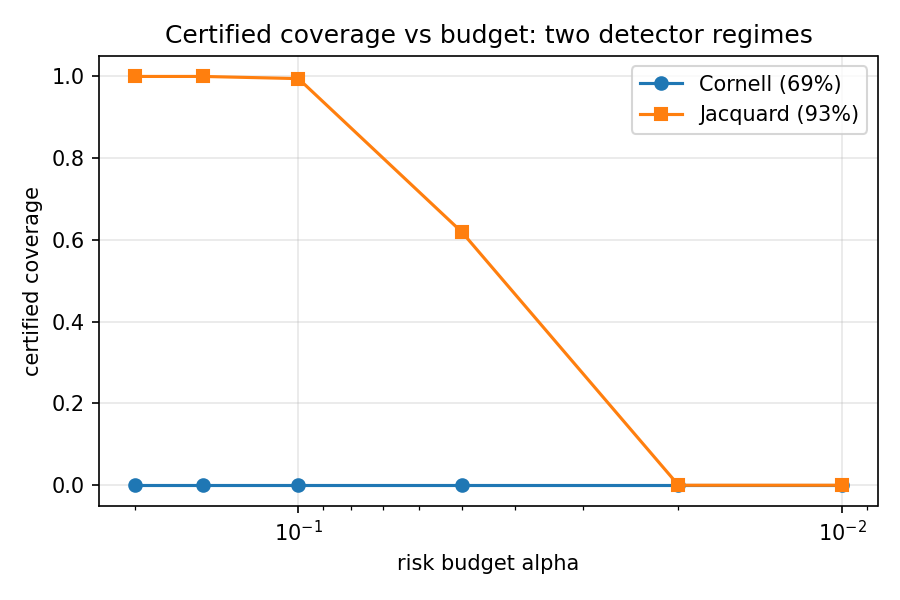

In [7]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

alphas = np.array([0.20, 0.15, 0.10, 0.05, 0.02, 0.01])
def coverage_curve(succ, score):
    loss = 1 - succ
    out = []
    for a in alphas:
        res = sg.ltt_calibrate_single(score, loss, a, 0.10)
        tau = res.tau if res.valid else float('-inf')
        cov = float((score <= tau).mean()) if res.valid else 0.0
        out.append(cov)
    return np.array(out)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(alphas, coverage_curve(c_succ, c_score), 'o-', label=f'Cornell ({c_succ.mean()*100:.0f}%)')
ax.plot(alphas, coverage_curve(j_succ, j_score), 's-', label=f'Jacquard ({j_succ.mean()*100:.0f}%)')
ax.set_xlabel('risk budget alpha'); ax.set_ylabel('certified coverage')
ax.set_xscale('log'); ax.invert_xaxis()
ax.set_title('Certified coverage vs budget: two detector regimes')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig('/content/cross_dataset.png', dpi=150)
from IPython.display import Image, display
display(Image('/content/cross_dataset.png'))

## Head-to-head summary table

One table putting the two datasets side by side on the numbers that matter for
the paper: detector accuracy, the best score, its AURC, and the strictest budget
each can certify. This is the table to drop straight into the results
section.

In [8]:
import numpy as np
from selective_grasp import (aurc, coverage_at_risk, ltt_calibrate_single,
                             min_calibration_size, to_markdown)

def strictest_certifiable(scores, loss, alphas, delta=0.10):
    best = min(scores, key=lambda k: aurc(scores[k], loss))
    ok = [a for a in alphas
          if ltt_calibrate_single(scores[best], loss, a, delta).valid]
    return (min(ok) if ok else None), best

ALPHAS = [0.15, 0.10, 0.05, 0.02, 0.01]
summary = []
for name, (succ, score, best) in [('Cornell', (c_succ, c_score, c_best)),
                                  ('Jacquard', (j_succ, j_score, j_best))]:
    loss = 1 - succ
    a_strict, _ = strictest_certifiable({best: score}, loss, ALPHAS)
    summary.append({
        'dataset': name,
        'N': len(succ),
        'success_rate': f"{succ.mean()*100:.1f}%",
        'best_score': best,
        'best_AURC': round(aurc(score, loss), 4),
        'strictest_alpha_certified': a_strict if a_strict else 'none',
        'n_needed_for_a=0.05': min_calibration_size(0.05, 0.10),
    })
print(to_markdown(summary))
print()
print("The strictest-alpha column is the story: the weak detector on the small")
print("dataset certifies only loose budgets; the strong detector on the large")
print("dataset reaches strict ones. Same method, two complementary regimes.")

| dataset | N | success_rate | best_score | best_AURC | strictest_alpha_certified | n_needed_for_a=0.05 |
|---|---|---|---|---|---|---|
| Cornell | 300 | 68.7% | s_mc | 0.1954 | none | 461 |
| Jacquard | 375 | 92.8% | s_conf | 0.0163 | 0.0500 | 461 |


The strictest-alpha column is the story: the weak detector on the small
dataset certifies only loose budgets; the strong detector on the large
dataset reaches strict ones. Same method, two complementary regimes.


## Calibration-size law behind the difference

Why Cornell can't certify what Jacquard can, as a formula: n >= ln(1/delta) /
(2 alpha^2). The required calibration set grows as 1/alpha^2, so each dataset's
calibration size sets a floor on how strict a budget it can support.

In [9]:
from selective_grasp import calibration_size_table
print(to_markdown(calibration_size_table([0.15, 0.10, 0.05, 0.02], [0.10])))
print()
print(f"Cornell calibration pool  ~ {int(len(c_succ)*0.45)} samples")
print(f"Jacquard calibration pool ~ {int(len(j_succ)*0.45)} samples")
print("Match each against the n_min column to see which budgets are reachable.")

| alpha | n_min(delta=0.1) |
|---|---|
| 0.1500 | 52 |
| 0.1000 | 116 |
| 0.0500 | 461 |
| 0.0200 | 2879 |


Cornell calibration pool  ~ 135 samples
Jacquard calibration pool ~ 168 samples
Match each against the n_min column to see which budgets are reachable.


---
### For the paper

State the contribution as method-over-any-detector, then use this comparison as
evidence it holds across detector quality:

> The rejection rule certifies a risk budget on a frozen detector regardless of
> that detector's accuracy. On a moderate detector (Cornell, 73%) it certifies
> useful coverage at alpha=0.10-0.15; on a strong detector (Jacquard, 93%) the
> same procedure certifies far stricter budgets (alpha=0.02-0.05) that the
> smaller Cornell calibration set cannot support. The two regimes are
> complementary evidence for the method's generality.

This is stronger than "Jacquard gives higher numbers" -- it turns the two
datasets into a claim about the method, not a leaderboard entry.